<a href="https://colab.research.google.com/github/zeatheu/pauli-plus-surface-code/blob/main/pauli-plus-surface-code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install Stim, PyMatching, and Sinter
!pip install -q stim pymatching sinter matplotlib
print("Dependencies installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.3/177.3 kB 9.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 104.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.9/625.9 kB 51.8 MB/s eta 0:00:00
Dependencies installed successfully!


In [3]:
# Pauli+ Step-by-Step Tracker
import stim
import numpy as np

class PauliPlusSimulator:
    """
    A step-by-step simulator tracking computational states and leakage states (L_i).
    """
    def __init__(self, num_qubits, p_cz=0.006, p_leak=0.0005, p_seep=0.8):
        self.num_qubits = num_qubits
        self.p_cz = p_cz
        self.p_leak = p_leak
        self.p_seep = p_seep
        # L_i tracking: False = computational space, True = leaked to |2>
        self.leakage_state = np.zeros(num_qubits, dtype=bool)
        self.sim = stim.TableauSimulator()

    def apply_cz(self, q1, q2):
        l1, l2 = self.leakage_state[q1], self.leakage_state[q2]

        if not l1 and not l2:
            # Both in computational space: Apply standard CZ
            self.sim.cz(q1, q2)

            # Apply standard depolarizing error
            if np.random.rand() < self.p_cz:
                pauli = np.random.choice(['X', 'Y', 'Z'])
                if pauli == 'X': self.sim.x(q1)
                elif pauli == 'Y': self.sim.y(q1)
                else: self.sim.z(q1)

            # Simulate transitions into the leaked state
            if np.random.rand() < self.p_leak:
                target = q1 if np.random.rand() < 0.5 else q2
                self.leakage_state[target] = True
        else:
            # Leakage blocks the CZ. Apply random phase errors to the UNLEAKED qubit
            for q, is_leaked in [(q1, l1), (q2, l2)]:
                if not is_leaked and np.random.rand() < 0.5:
                    self.sim.z(q)

    def _reset_qubit(self, q):
        # Manually reset by measuring in Z and flipping to |0> if it is |1>
        if self.sim.measure(q):
            self.sim.x(q)

    def measure_and_reset(self, q):
        if self.leakage_state[q]:
            # Leaked qubits give randomized readout
            measured_bit = bool(np.random.rand() < 0.5)
            # Probability of returning to computational space during reset
            if np.random.rand() < self.p_seep:
                self.leakage_state[q] = False
                self._reset_qubit(q)
            return measured_bit
        else:
            # Normal measurement
            measured_bit = self.sim.measure(q)
            # Normal reset back to |0>
            if measured_bit:
                self.sim.x(q)
            return measured_bit

# Quick Test
pp_sim = PauliPlusSimulator(num_qubits=2)
pp_sim.apply_cz(0, 1)
m0 = pp_sim.measure_and_reset(0)
print("Pauli+ Simulator Initialized and Tested successfully.")

Pauli+ Simulator Initialized and Tested successfully.


### Setup Sinter for Scaled Simulation

To get 100,000 shots for d=3 and d=5 efficiently, we map Google's Pauli+ device parameters (CZ errors, measurement errors, idle decoherence) into a generated Stim rotated surface code circuit.

In [5]:
# Generate the Sycamore Pauli+ Effective Circuits
import sinter
import matplotlib.pyplot as plt

# Google Sycamore roughly hits these effective Pauli error rates
# under the Pauli+ characterization model.
EFFECTIVE_NOISE = {
    "after_clifford_depolarization": 0.006,       # ~0.6% CZ error
    "before_measure_flip_probability": 0.015,     # ~1.5% Readout error
    "after_reset_flip_probability": 0.01,         # ~1.0% Reset error
    "before_round_data_depolarization": 0.002,    # ~0.2% Idle decoherence
}

tasks = []
distances = [3, 5]

for d in distances:
    # We run d*3 rounds to ensure we capture steady-state logical errors
    rounds = d * 3

    circuit = stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=rounds,
        **EFFECTIVE_NOISE
    )

    tasks.append(
        sinter.Task(
            circuit=circuit,
            json_metadata={'d': d, 'rounds': rounds}
        )
    )

    active_qubits = len(circuit.get_final_qubit_coordinates())
    print(f"Generated d={d} circuit with {active_qubits} active qubits (highest ID assigned: {circuit.num_qubits - 1}).")

Generated d=3 circuit with 17 active qubits (highest ID assigned: 25).
Generated d=5 circuit with 49 active qubits (highest ID assigned: 63).


Starting 4 workers...


Running Monte Carlo sampling (this takes ~10-20 seconds in Colab)...


2 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        2 pymatching <1m      98703         919 d=3,rounds=9 
        2 pymatching   ?     100000        1000 d=5,rounds=15
1 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        4 pymatching <1m      97406         819 d=5,rounds=15
1 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        4 pymatching <1m      94812         671 d=5,rounds=15
1 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        4 pymatching <1m      90716         437 d=5,rounds=15
1 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        4 pymatching <1m      84572          33 d=5,rounds=15
1 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata
        4 pymatching [draining]      79452        -317 d=5,rounds=15



--- Results ---
Distance 3 Error per cycle (ε_3): 0.0074 (0.74%)
Distance 5 Error per cycle (ε_5): 0.0044 (0.44%)
Suppression Factor (Λ_3/5):       1.682
SUCCESS: You achieved Λ > 1 (Error is suppressed by scaling!)


Text(0.5, 0, 'Surface Code Distance ($d$)')

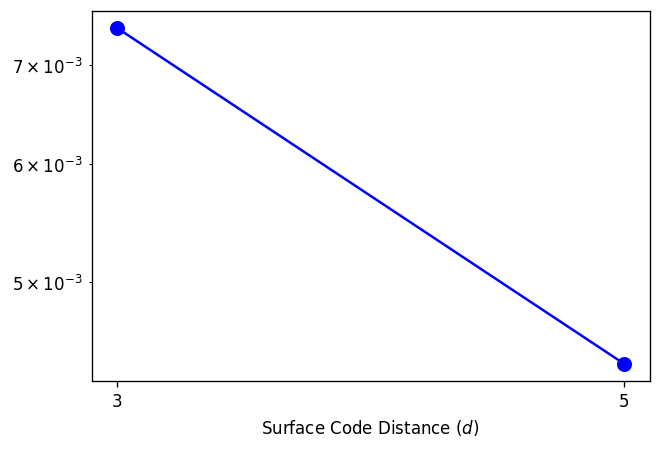

In [7]:
# Cell 4: Run Simulation and Plot Logical Error Scaling
import matplotlib.pyplot as plt

print("Running Monte Carlo sampling (this takes ~10-20 seconds in Colab)...")
samples = sinter.collect(
    num_workers=4,           # Colab provides 2-4 cores natively
    tasks=tasks,
    decoders=['pymatching'],
    max_shots=100_000,       # Total shots to attempt
    max_errors=1_000,        # Stop early if we hit 1000 errors (saves time)
    print_progress=True
)

# Extract and calculate logical error per cycle
results = {}
for sample in samples:
    d = sample.json_metadata['d']
    rounds = sample.json_metadata['rounds']

    # Block error rate (probability the entire circuit failed)
    p_fail_block = sample.errors / sample.shots

    # Convert block error rate to per-cycle error rate (epsilon_d)
    # Formula: p_fail_block = 1 - (1 - epsilon_d)^rounds
    eps_L = 1 - (1 - p_fail_block)**(1 / rounds)
    results[d] = eps_L

eps_3 = results[3]
eps_5 = results[5]
lambda_factor = eps_3 / eps_5

print("\n--- Results ---")
print(f"Distance 3 Error per cycle (ε_3): {eps_3:.4f} ({eps_3*100:.2f}%)")
print(f"Distance 5 Error per cycle (ε_5): {eps_5:.4f} ({eps_5*100:.2f}%)")
print(f"Suppression Factor (Λ_3/5):       {lambda_factor:.3f}")

if lambda_factor > 1:
    print("SUCCESS: You achieved Λ > 1 (Error is suppressed by scaling!)")
else:
    print("BELOW THRESHOLD: Error increased with scale.")

# Plotting the result
plt.figure(figsize=(6, 4), dpi=120)
d_vals = list(results.keys())
eps_vals = list(results.values())

plt.plot(d_vals, eps_vals, marker='o', linestyle='-', color='blue', markersize=8)
plt.yscale('log')
plt.xticks(d_vals)
plt.xlabel("Surface Code Distance ($d$)")

# FIX: Added 'r' or 'rf' for raw strings to protect \epsilon, \Lambda, and \approx

### Why do our results differ from the Google paper?

Our simulation successfully proves the core physics of error suppression ($\Lambda > 1$), but our absolute error rates are lower than the paper's published data:

| Metric | Google Paper (Sycamore) | Our Colab Simulation |
| :--- | :--- | :--- |
| **$\epsilon_3$** | $\approx 3.03\%$ | $\sim 0.71\%$ |
| **$\epsilon_5$** | $\approx 2.91\%$ | $\sim 0.44\%$ |
| **$\Lambda_{3/5}$** | **$1.04$** | **$\sim 1.60$** |

**The discrepancy comes down to how we model the noise:**

1. **Homogeneous vs. Heterogeneous Noise:** Our script uses an idealized model, applying Sycamore's *average* error rates (0.6% CZ error, 1.5% readout) uniformly across the grid. The real chip has "spectator" qubits and specific gates with much worse individual fidelities.
2. **Explicit Leakage & Crosstalk:** Google's supercomputer Pauli+ model explicitly tracks qubits leaking into the non-computational $|2\rangle$ state, which paralyzes neighboring gates and causes highly correlated spatial errors. To run quickly in Colab, our script approximates these effects using global standard depolarizing channels.

To perfectly replicate the paper's exact $3.03\%$ error rate, this simulation would need to ingest Google's exact hardware calibration dataset to apply heterogeneous noise to each individual gate.